In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# Libraries
import numpy as np #operasi numerik
import pandas as pd #manipulasi data
import matplotlib.pyplot as plt #visualisasi
import seaborn as sns

#split data
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
#evaluasi performa
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

#model utama yang dipakai
from xgboost import XGBClassifier


In [ ]:
data = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/ANEMIA/anemia.csv')  # ganti sesuai nama file

print(f"Shape of dataset -> {data.shape}")
print(data.info())


data.head()


Shape of dataset -> (1421, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1421 entries, 0 to 1420
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Gender      1421 non-null   int64  
 1   Hemoglobin  1421 non-null   float64
 2   MCH         1421 non-null   float64
 3   MCHC        1421 non-null   float64
 4   MCV         1421 non-null   float64
 5   Result      1421 non-null   int64  
dtypes: float64(4), int64(2)
memory usage: 66.7 KB
None


,Gender,Hemoglobin,MCH,MCHC,MCV,Result
0,1,14.9,22.7,29.1,83.7,0
1,0,15.9,25.4,28.3,72.0,0
2,0,9.0,21.5,29.6,71.2,1
3,0,14.9,16.0,31.4,87.5,0
4,1,14.7,22.0,28.2,99.5,0


<a id="functions"><b style="font-size:1.2em">Definitions of functions ⌨️</b><a>

In [ ]:
def set_style(ax, left=True, bottom=False, axis_grid="y"):
    sns.despine(ax=ax, left=left, bottom=bottom)
    ax.grid(axis=axis_grid, linewidth=0.2, color="black")

In [ ]:
# orange, dark blue, light blue
colors = ["#fca311", "#14213d", "#00b4d8"]

In [ ]:
def cdf_plot(df, x, ax, hue=None, palette=None, main_color=colors[1]):

    sns.kdeplot(data=df, x=x, hue=hue, ax=ax, color=main_color,
                palette=palette,
                cumulative=True, warn_singular=False, linewidth=4, common_norm=False)

    set_style(ax)

In [ ]:
def count(df, x, ax, main_color=colors[0], hue=None, palette=None):

    sns.countplot(data=df, x=x, ax=ax,
                  color=main_color, saturation=0.8, linewidth=3, edgecolor="black",
                  hue=hue, palette=palette)

    for container in ax.containers:
        ax.bar_label(container, color="black", fontsize=20)

    ax.set_ylabel("")
    ax.set_xlabel(x, fontsize=15)
    ax.tick_params(axis='y', which='both', left=False, right=False)


    set_style(ax)

In [ ]:
def hist(df, x, ax, hue=None, palette=None, main_color=colors[0], second_color=colors[1]):

    alpha = 0.8
    if hue:
        alpha = 0.3

    sns.histplot(data=df, x=x, ax=ax,
                 hue=hue, palette=palette,
                 color=main_color, linewidth=3, bins=20, alpha=alpha,
                 kde=True, line_kws={"linewidth":3, "linestyle":"--"}
                )
    ax.lines[0].set_color(second_color)

    ax.set_ylabel("Number of observation")
    ax.set_xlabel(x, fontsize="x-large")

    set_style(ax)


<a id="numeric"><b style="font-size:1.2em">Numeric Variables Distribution 🔢</b><a>

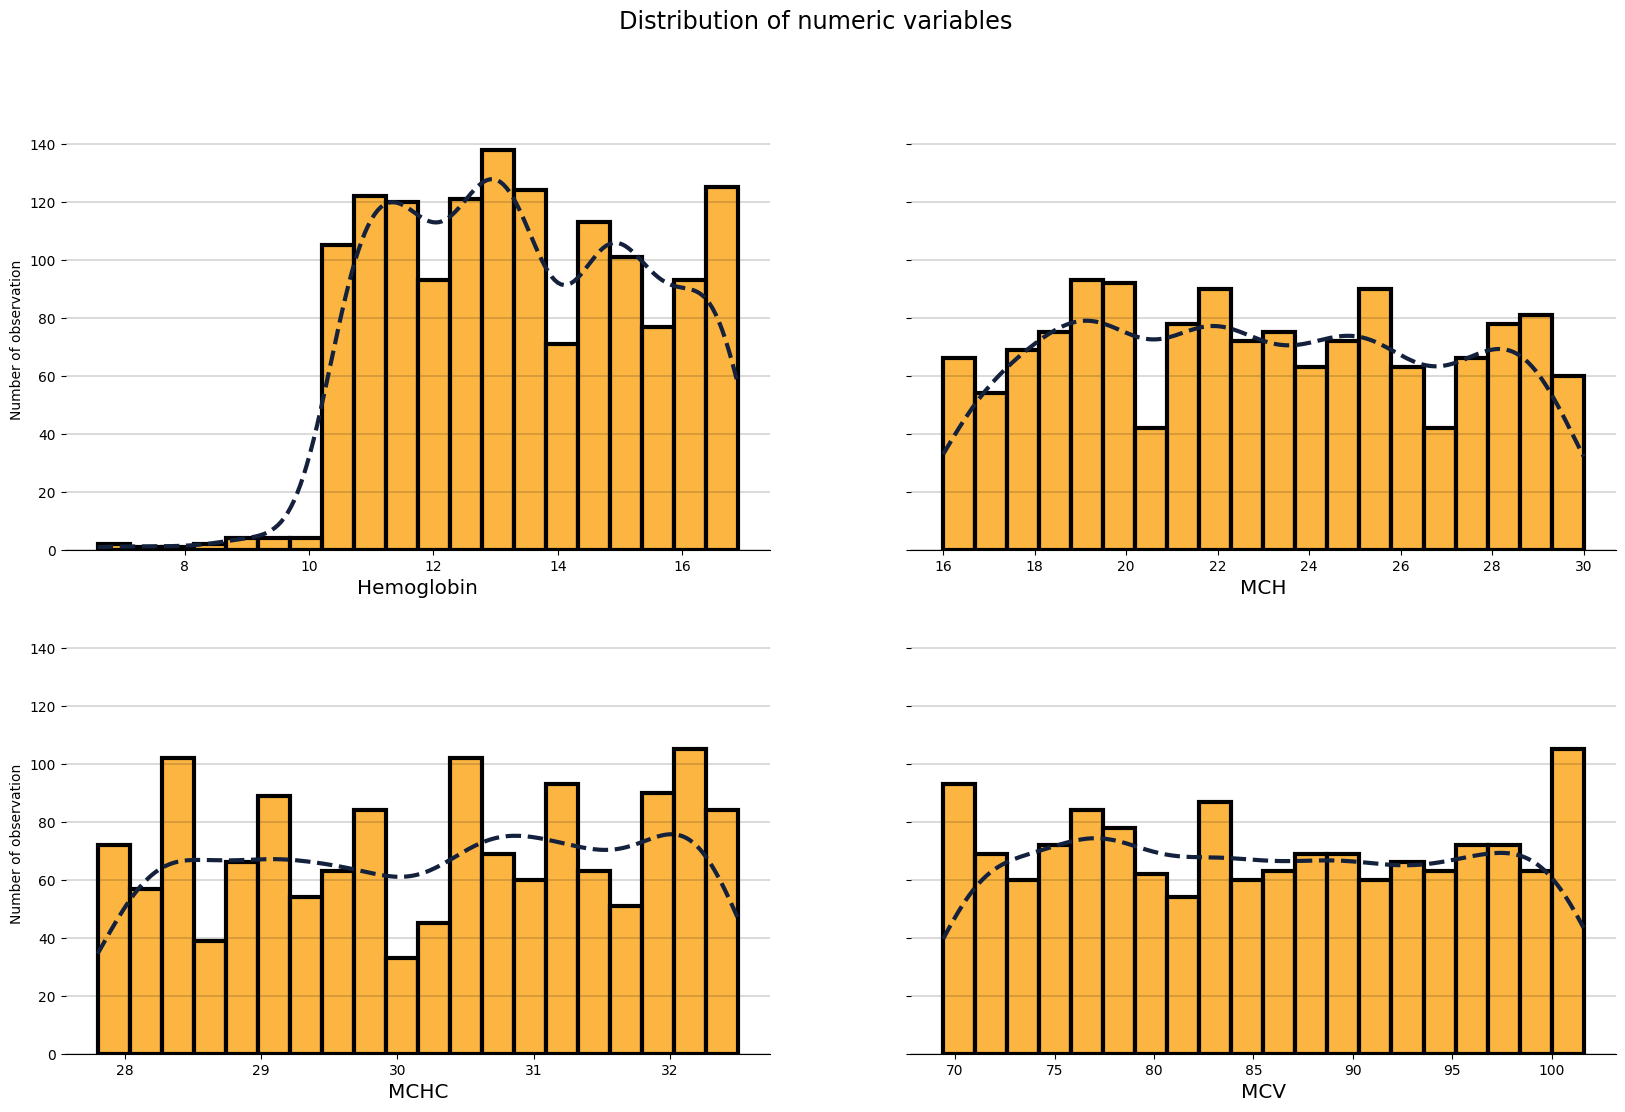

In [ ]:
numeric_cols = [col for col in data.columns if data[col].dtype == float]

fig, axs = plt.subplots(2, 2, figsize=(20, 12), sharey=True)

for i, col in enumerate(numeric_cols):
    ax = axs[i // 2][i % 2]

    hist(data, col, ax)

fig.suptitle("Distribution of numeric variables", fontsize="xx-large")

plt.show()

Di antara kolom-kolom numerik, kita dapat melihat bahwa:

“Hemoglobin” memiliki distribusi yang miring ke kanan. Sedikit pengetahuan tentang anemia memberitahu kita bahwa kadar hemoglobin yang rendah adalah ciri khas penderita anemia, jadi distribusi ini tidak mengejutkan.

Semua kolom lainnya memiliki distribusi yang seragam. Kita akan melihat nanti apakah kategori-kategori tersebut menunjukkan perbedaan dalam fitur-fitur ini.

<a id="categorical"><b style="font-size:1.2em">Categorical Variables Distribution 📊</b><a>

In [ ]:
cat_cols = [col for col in data.columns if data[col].dtype == int]

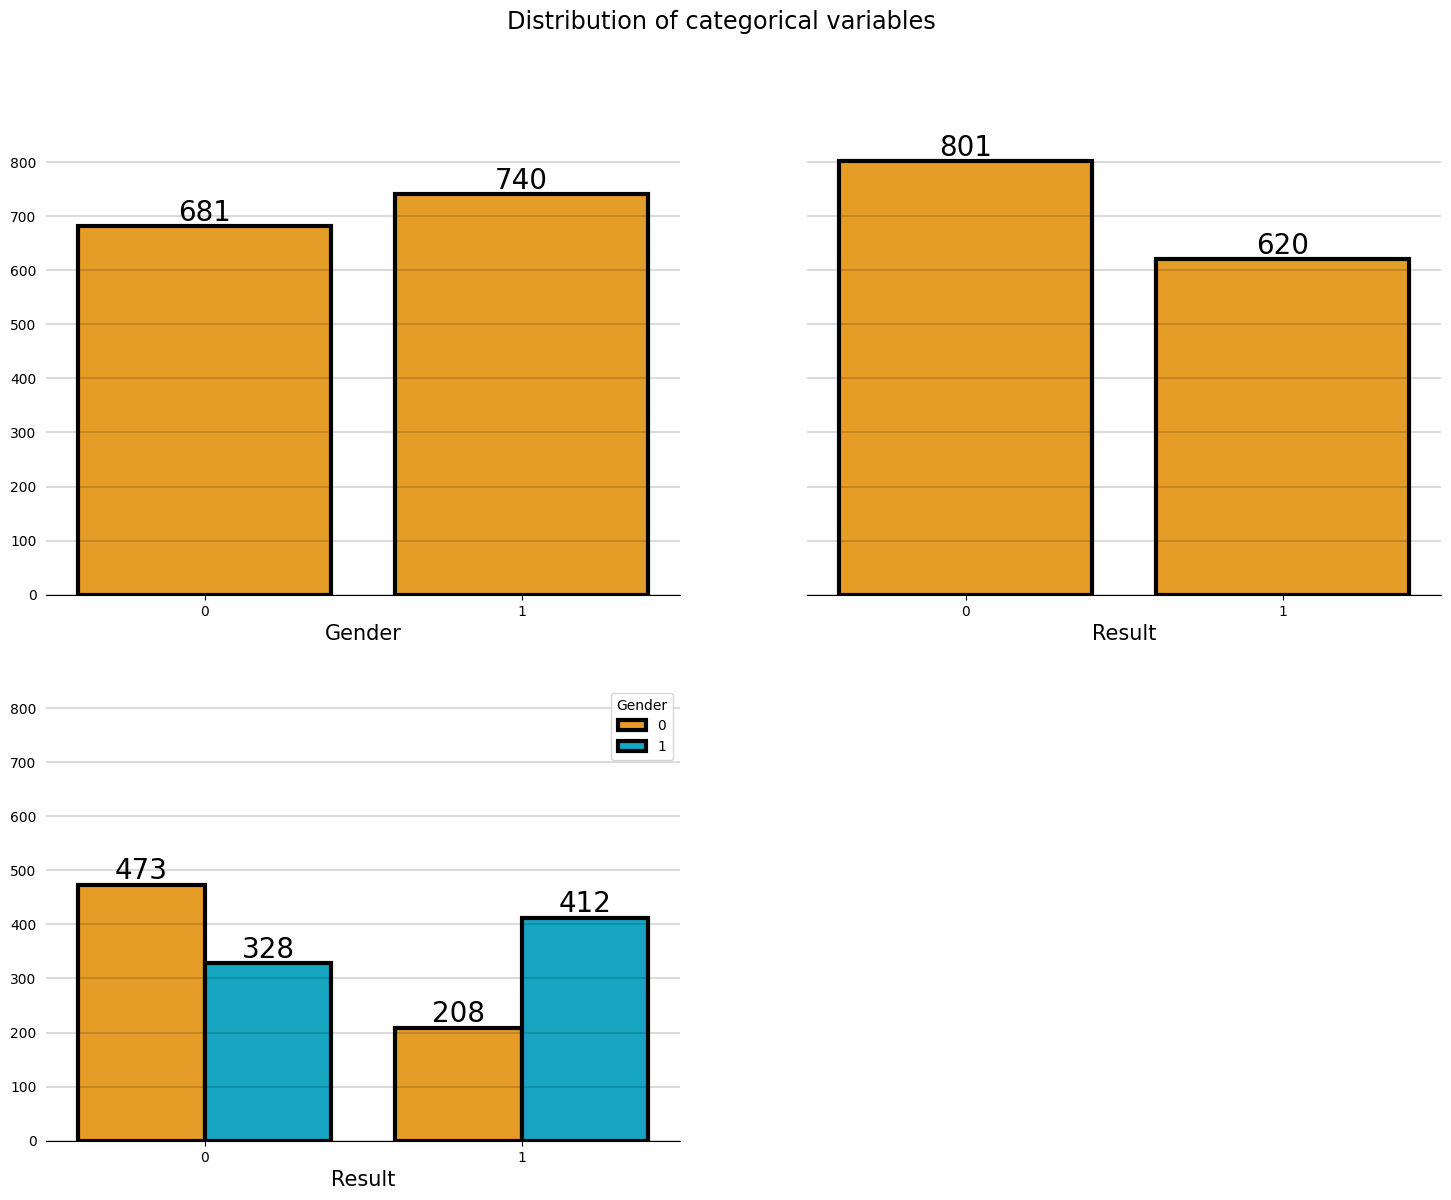

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(18, 13), sharey=True)

for i, col in enumerate(cat_cols):
    count(data, col, axs[0][i])

count(data, "Result", axs[1][0], hue="Gender",palette=[colors[0], colors[2]])

fig.delaxes(axs[1,1])
fig.suptitle("Distribution of categorical variables", fontsize="xx-large")

plt.show()

Variabel kategorikal terdistribusi dengan baik dalam dataset, tanpa ketidakseimbangan yang berlebihan.

<a id="correlation"><b style="font-size:1.2em">Correlation with "Results"🔍</b><a>

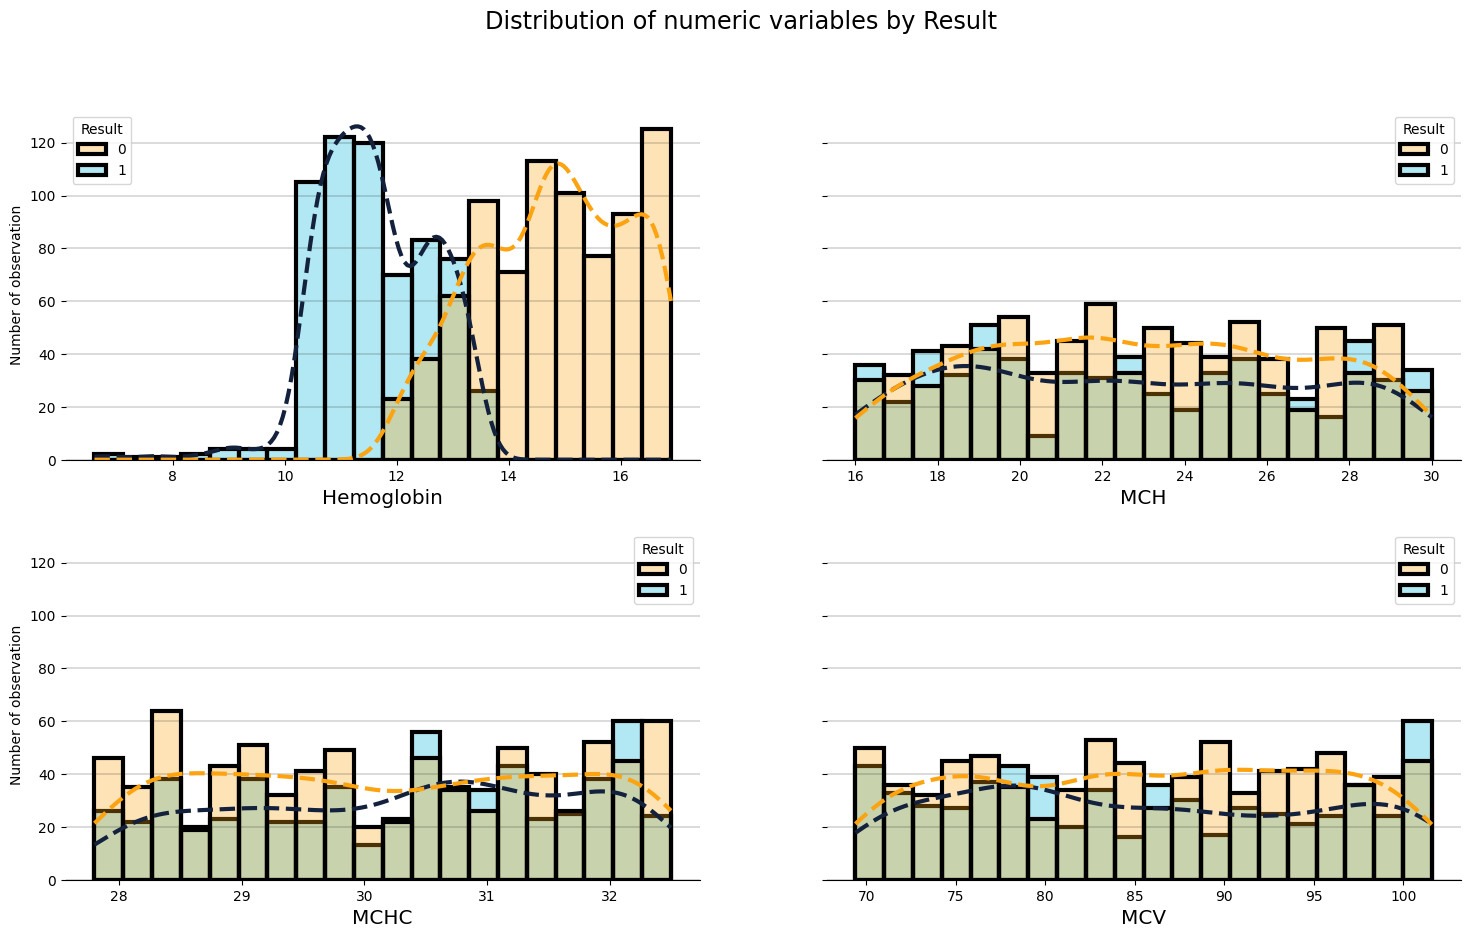

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(18, 10), sharey=True)

for i, col in enumerate(numeric_cols):
    ax = axs[i // 2][i % 2]

    hist(data, col, ax, hue="Result", palette=[colors[0], colors[2]])

fig.suptitle("Distribution of numeric variables by Result", fontsize="xx-large")

plt.show()

<a id="correlation"><b style="font-size:1.2em">PREPROCESSING DATA
🔍</b><a>

Data Cleaning

In [ ]:
data.info()

# Tabel missing value
missing_table = data.isnull().sum().to_frame(name='Missing Value')
missing_table

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1421 entries, 0 to 1420
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Gender      1421 non-null   int64  
 1   Hemoglobin  1421 non-null   float64
 2   MCH         1421 non-null   float64
 3   MCHC        1421 non-null   float64
 4   MCV         1421 non-null   float64
 5   Result      1421 non-null   int64  
dtypes: float64(4), int64(2)
memory usage: 66.7 KB


,Missing Value
Gender,0
Hemoglobin,0
MCH,0
MCHC,0
MCV,0
Result,0


In [ ]:
# Persentase missing value
missing_percent = (data.isnull().sum() / len(data)) * 100

missing_summary = pd.DataFrame({
    'Missing Value': data.isnull().sum(),
    'Persentase (%)': missing_percent
})

missing_summary


,Missing Value,Persentase (%)
Gender,0,0.0
Hemoglobin,0,0.0
MCH,0,0.0
MCHC,0,0.0
MCV,0,0.0
Result,0,0.0


In [ ]:
# Cek apakah ada missing value
if data.isnull().values.any():
    print("Dataset memiliki missing value.")
else:
    print("Dataset tidak memiliki missing value (bersih).")

Dataset tidak memiliki missing value (bersih).


Feature Label Separation

In [ ]:
# Pisahkan fitur dan label
X = data.drop (columns='Result')  # fitur
y = data['Result']                 # label

# Tampilkan 5 data pertama fitur
print("=== Data Fitur (X) ===")
display(X.head())

# Tampilkan 5 data pertama label
print("=== Label (y) ===")
display(y.head())



=== Data Fitur (X) ===


,Gender,Hemoglobin,MCH,MCHC,MCV
0,1,14.9,22.7,29.1,83.7
1,0,15.9,25.4,28.3,72.0
2,0,9.0,21.5,29.6,71.2
3,0,14.9,16.0,31.4,87.5
4,1,14.7,22.0,28.2,99.5


=== Label (y) ===


,Result
0,0
1,0
2,1
3,0
4,0


Feature Selection

In [ ]:
xgb_temp = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=7

)

xgb_temp.fit(X_train, y_train)

importances = xgb_temp.feature_importances_

feature_importance_df = pd.DataFrame({
    'Fitur': X_train.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

In [ ]:
selected_features = feature_importance_df['Fitur'].head(3).tolist()

X_train_sel = X_train[selected_features]
X_test_sel  = X_test[selected_features]


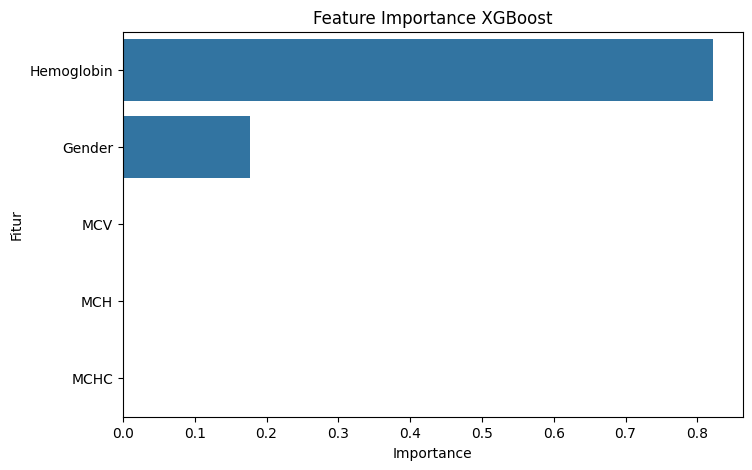

In [ ]:
plt.figure(figsize=(8,5))
sns.barplot(
    data=feature_importance_df,
    x='Importance',
    y='Fitur'
)
plt.title("Feature Importance XGBoost")
plt.show()

Gender = fitur demografis

Bisa menyebabkan: Bias model, Over-dominance (seperti yang kamu lihat)

Akibatnya:
Fitur medis (MCH, MCV, MCHC) jadi “tidak terlihat penting”

Setelah dihapus: Model fokus ke fitur klinis yang relevan

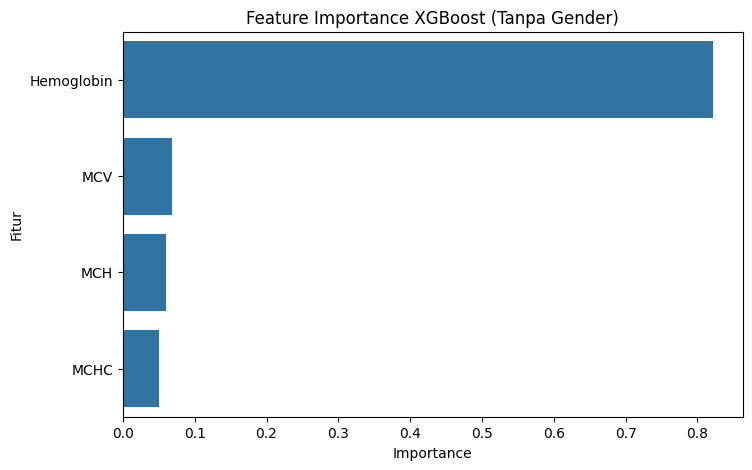

In [ ]:
#Menghapus Fitur Gender
X_train_nogender = X_train.drop(columns=['Gender'])
X_test_nogender  = X_test.drop(columns=['Gender'])

#Menghitung ulang Fitur importance
xgb_temp.fit(X_train_nogender, y_train)

importances_new = xgb_temp.feature_importances_

feature_importance_new = pd.DataFrame({
    'Fitur': X_train_nogender.columns,
    'Importance': importances_new
}).sort_values(by='Importance', ascending=False)

#Visualisasi
plt.figure(figsize=(8,5))
sns.barplot(
    data=feature_importance_new,
    x='Importance',
    y='Fitur'
)
plt.title("Feature Importance XGBoost (Tanpa Gender)")
plt.show()

In [ ]:
selected_features = feature_importance_new['Fitur'].head(3).tolist()

X_train_sel = X_train_nogender[selected_features]
X_test_sel  = X_test_nogender[selected_features]

Split Data

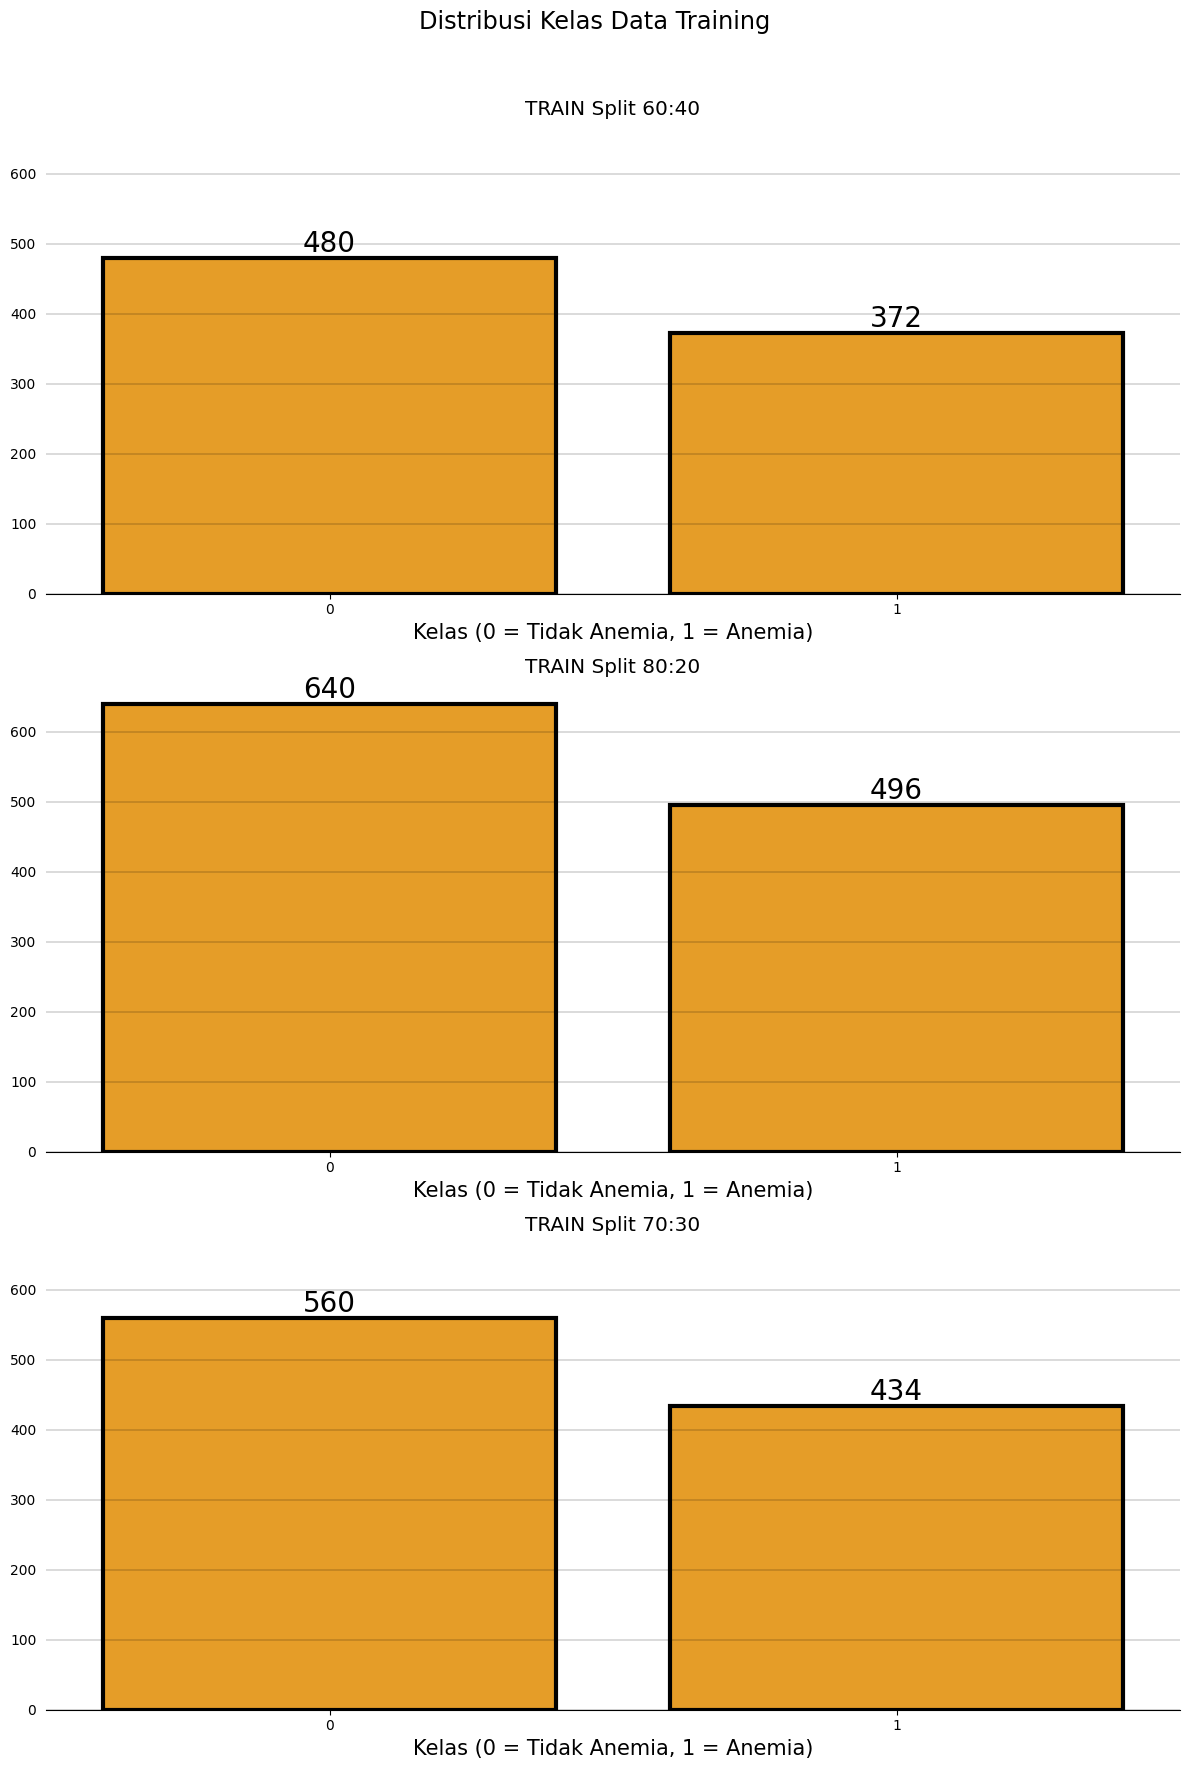

In [ ]:
# Dataset dibagi menggunakan skema hold-out dengan rasio 80% data latih dan 20% data uji
splits = [ (0.4, "60:40"), (0.2, "80:20"), (0.3, "70:30")]

fig, axes = plt.subplots(len(splits), 1, figsize=(12, 18), sharey=True)
fig.suptitle(
    "Distribusi Kelas Data Training",
    fontsize="xx-large"
)

for i, (test_size, label) in enumerate(splits):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=13,
        stratify=y
    )

    # Buat DataFrame khusus TRAIN
    train_df = y_train.value_counts().reset_index()
    train_df.columns = ['Result', 'Count']
    train_df = train_df.sort_values('Result')

    train_df['Percentage'] = (train_df['Count'] / train_df['Count'].sum()) * 100

    ax = axes[i]

    # Pakai fungsi count() milikmu
    count(
        df=y_train.to_frame(name='Result'),
        x='Result',
        ax=ax,
        main_color=colors[0]
    )


    ax.set_title(f"TRAIN Split {label}", fontsize="x-large")
    ax.set_xlabel("Kelas (0 = Tidak Anemia, 1 = Anemia)")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()



<a id="model-search"><b style="font-size:1.2em">Modelling XGBOOST
💻</b><a>

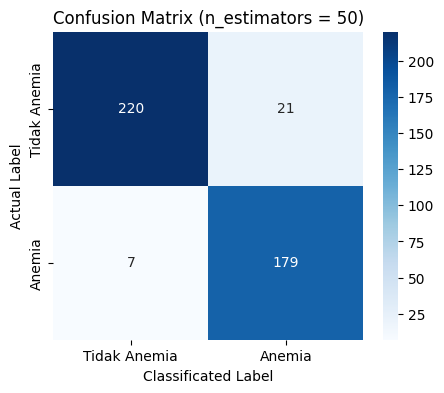

              precision    recall  f1-score   support

           0       0.97      0.91      0.94       241
           1       0.90      0.96      0.93       186

    accuracy                           0.93       427
   macro avg       0.93      0.94      0.93       427
weighted avg       0.94      0.93      0.93       427



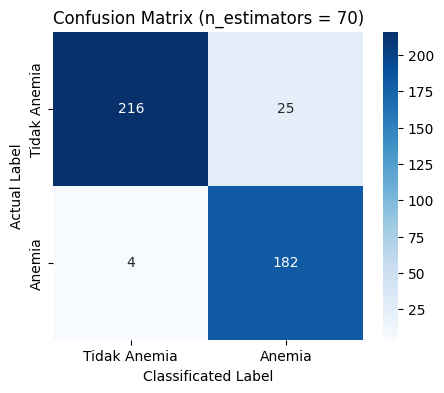

              precision    recall  f1-score   support

           0       0.98      0.90      0.94       241
           1       0.88      0.98      0.93       186

    accuracy                           0.93       427
   macro avg       0.93      0.94      0.93       427
weighted avg       0.94      0.93      0.93       427



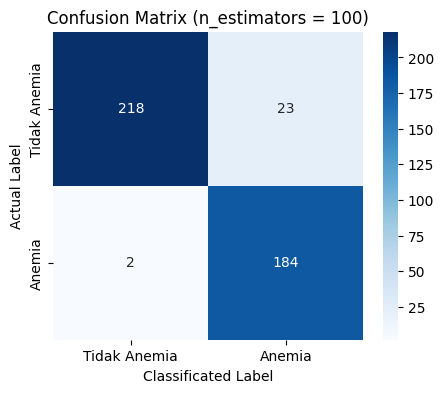

              precision    recall  f1-score   support

           0       0.99      0.90      0.95       241
           1       0.89      0.99      0.94       186

    accuracy                           0.94       427
   macro avg       0.94      0.95      0.94       427
weighted avg       0.95      0.94      0.94       427



,n_estimators,Accuracy,Precision,Recall,F1-Score
0,50,0.934426,0.895000,0.962366,0.927461
1,70,0.932084,0.879227,0.978495,0.926209
2,100,0.941452,0.888889,0.989247,0.936387


In [ ]:
from sklearn.metrics import confusion_matrix

result = []

for n in [50, 70, 100]:
    xgb_model = XGBClassifier(
        objective='binary:logistic',
        n_estimators=n,
        max_depth=4,
        learning_rate=0.1,
        subsample=0.2,
        colsample_bytree=0.6,
        eval_metric='logloss',
        random_state=7
    )

    # Latih model
    xgb_model.fit(X_train_sel, y_train)

    # Prediksi
    y_pred = xgb_model.predict(X_test_sel)

    # Evaluasi metrik
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    result.append([n, acc, prec, rec, f1])

    # Confusion Matrix (HARUS DI DALAM LOOP)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5,4))
    sns.heatmap(
        cm,
        annot=True,        # tampilkan angka
        fmt='d',           # format integer
        cmap='Blues',      # warna
        xticklabels=['Tidak Anemia', 'Anemia'],
        yticklabels=['Tidak Anemia', 'Anemia']
    )

    plt.title(f'Confusion Matrix (n_estimators = {n})')
    plt.xlabel('Classificated Label')
    plt.ylabel('Actual Label')
    plt.show()

    #Classification Report
    print(classification_report(y_test, y_pred))

# Tabel evaluasi
result_df = pd.DataFrame(
    result,
    columns=['n_estimators', 'Accuracy', 'Precision', 'Recall', 'F1-Score']
)

result_df



In [ ]:
# Gabungkan X_test dengan y_test dan y_pred
X_test_df = pd.DataFrame(X_test, columns=['Hemoglobin', 'MCH', 'MCHC', 'MCV'])
X_test_df['Actual'] = y_test.values
X_test_df['Predicted'] = y_pred

# Pisahkan FP dan FN
FP_data = X_test_df[(X_test_df['Actual'] == 0) & (X_test_df['Predicted'] == 1)]
FN_data = X_test_df[(X_test_df['Actual'] == 1) & (X_test_df['Predicted'] == 0)]

print("=== FALSE POSITIVE (Tidak Anemia tapi diprediksi Anemia) ===")
print(FP_data.describe())

print("\n=== FALSE NEGATIVE (Anemia tapi diprediksi Tidak Anemia) ===")
print(FN_data.describe())

# Bandingkan dengan rata-rata keseluruhan kelas
print("\n=== Rata-rata Hemoglobin per kelas (data asli) ===")
print(X_test_df.groupby('Actual')['Hemoglobin'].describe())

=== FALSE POSITIVE (Tidak Anemia tapi diprediksi Anemia) ===
       Hemoglobin        MCH       MCHC         MCV  Actual  Predicted
count   23.000000  23.000000  23.000000   23.000000    23.0       23.0
mean    12.691304  22.039130  29.978261   88.413043     0.0        1.0
std      0.491670   4.579474   1.230283   12.255326     0.0        0.0
min     12.000000  16.200000  28.000000   70.000000     0.0        1.0
25%     12.150000  17.300000  29.150000   74.400000     0.0        1.0
50%     12.800000  21.400000  29.400000   94.200000     0.0        1.0
75%     13.100000  26.300000  30.900000   99.100000     0.0        1.0
max     13.300000  29.100000  32.400000  101.500000     0.0        1.0

=== FALSE NEGATIVE (Anemia tapi diprediksi Tidak Anemia) ===
       Hemoglobin        MCH       MCHC        MCV  Actual  Predicted
count    2.000000   2.000000   2.000000   2.000000     2.0        2.0
mean    12.600000  22.000000  28.150000  93.600000     1.0        0.0
std      0.848528   2.262742

In [ ]:
#Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=7)
lr_model.fit(X_train_sel, y_train)

y_pred_lr = lr_model.predict(X_test_sel)

print("=== Logistic Regression ===")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1-score:", f1_score(y_test, y_pred_lr))

=== Logistic Regression ===
Accuracy: 0.8969555035128806
Precision: 0.8697916666666666
Recall: 0.8978494623655914
F1-score: 0.8835978835978836


In [ ]:
#Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=7)
rf_model.fit(X_train_sel, y_train)

y_pred_rf = rf_model.predict(X_test_sel)

print("\n=== Random Forest ===")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-score:", f1_score(y_test, y_pred_rf))


=== Random Forest ===
Accuracy: 0.9836065573770492
Precision: 0.9735449735449735
Recall: 0.989247311827957
F1-score: 0.9813333333333333


In [ ]:
results = pd.DataFrame({
    "Model": ["XGBoost", "Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    "F1-score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf)
    ]
})

print(results)

                 Model  Accuracy  F1-score
0              XGBoost  0.941452  0.936387
1  Logistic Regression  0.896956  0.883598
2        Random Forest  0.983607  0.981333
